In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
import os

print(os.getcwd())

C:\Users\User


In [7]:
print(os.listdir())

['.anaconda', '.conda', '.continuum', '.ipynb_checkpoints', '.ipython', '.jupyter', '.vscode', 'api-ms-win-core-console-l1-1-0.dll', 'api-ms-win-core-datetime-l1-1-0.dll', 'api-ms-win-core-debug-l1-1-0.dll', 'api-ms-win-core-errorhandling-l1-1-0.dll', 'api-ms-win-core-file-l1-1-0.dll', 'api-ms-win-core-file-l1-2-0.dll', 'api-ms-win-core-file-l2-1-0.dll', 'api-ms-win-core-handle-l1-1-0.dll', 'api-ms-win-core-heap-l1-1-0.dll', 'api-ms-win-core-interlocked-l1-1-0.dll', 'api-ms-win-core-libraryloader-l1-1-0.dll', 'api-ms-win-core-localization-l1-2-0.dll', 'api-ms-win-core-memory-l1-1-0.dll', 'api-ms-win-core-namedpipe-l1-1-0.dll', 'api-ms-win-core-processenvironment-l1-1-0.dll', 'api-ms-win-core-processthreads-l1-1-0.dll', 'api-ms-win-core-processthreads-l1-1-1.dll', 'api-ms-win-core-profile-l1-1-0.dll', 'api-ms-win-core-rtlsupport-l1-1-0.dll', 'api-ms-win-core-string-l1-1-0.dll', 'api-ms-win-core-synch-l1-1-0.dll', 'api-ms-win-core-synch-l1-2-0.dll', 'api-ms-win-core-sysinfo-l1-1-0.dll', 

In [8]:
import os

os.makedirs("dataset", exist_ok=True)

print("Dataset folder created successfully!")

Dataset folder created successfully!


In [9]:
print(os.listdir())

['.anaconda', '.conda', '.continuum', '.ipynb_checkpoints', '.ipython', '.jupyter', '.vscode', 'api-ms-win-core-console-l1-1-0.dll', 'api-ms-win-core-datetime-l1-1-0.dll', 'api-ms-win-core-debug-l1-1-0.dll', 'api-ms-win-core-errorhandling-l1-1-0.dll', 'api-ms-win-core-file-l1-1-0.dll', 'api-ms-win-core-file-l1-2-0.dll', 'api-ms-win-core-file-l2-1-0.dll', 'api-ms-win-core-handle-l1-1-0.dll', 'api-ms-win-core-heap-l1-1-0.dll', 'api-ms-win-core-interlocked-l1-1-0.dll', 'api-ms-win-core-libraryloader-l1-1-0.dll', 'api-ms-win-core-localization-l1-2-0.dll', 'api-ms-win-core-memory-l1-1-0.dll', 'api-ms-win-core-namedpipe-l1-1-0.dll', 'api-ms-win-core-processenvironment-l1-1-0.dll', 'api-ms-win-core-processthreads-l1-1-0.dll', 'api-ms-win-core-processthreads-l1-1-1.dll', 'api-ms-win-core-profile-l1-1-0.dll', 'api-ms-win-core-rtlsupport-l1-1-0.dll', 'api-ms-win-core-string-l1-1-0.dll', 'api-ms-win-core-synch-l1-1-0.dll', 'api-ms-win-core-synch-l1-2-0.dll', 'api-ms-win-core-sysinfo-l1-1-0.dll', 

In [10]:
print(os.listdir("dataset"))

['diabetic_data.csv']


In [11]:
import pandas as pd

df = pd.read_csv("dataset/diabetic_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [13]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 101766
Columns: 50


In [14]:
df.tail()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


In [15]:
print(df.columns.tolist())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [17]:
df.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [18]:
df.isin(["?"]).sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [21]:
df = df.replace("?", np.nan)

In [22]:
df.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [23]:
columns_to_remove = [
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code"
]

df = df.drop(columns=columns_to_remove)

print("Columns removed successfully!")
print("New dataset shape:", df.shape)

Columns removed successfully!
New dataset shape: (101766, 45)


In [24]:
df.isnull().sum()

encounter_id                   0
patient_nbr                    0
race                        2273
gender                         0
age                            0
admission_type_id              0
discharge_disposition_id       0
admission_source_id            0
time_in_hospital               0
num_lab_procedures             0
num_procedures                 0
num_medications                0
number_outpatient              0
number_emergency               0
number_inpatient               0
diag_1                        21
diag_2                       358
diag_3                      1423
number_diagnoses               0
metformin                      0
repaglinide                    0
nateglinide                    0
chlorpropamide                 0
glimepiride                    0
acetohexamide                  0
glipizide                      0
glyburide                      0
tolbutamide                    0
pioglitazone                   0
rosiglitazone                  0
acarbose  

In [25]:
df["race"] = df["race"].fillna("Unknown")
df["diag_1"] = df["diag_1"].fillna("Unknown")
df["diag_2"] = df["diag_2"].fillna("Unknown")
df["diag_3"] = df["diag_3"].fillna("Unknown")

print("Missing values handled successfully!")

Missing values handled successfully!


In [26]:
df.isnull().sum().sum()

np.int64(0)

In [27]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 101766
Columns: 45


In [29]:
df["readmission"] = df["readmitted"].apply(
    lambda x: 0 if x == "NO" else 1
)

In [30]:
df["readmission"].value_counts()

readmission
0    54864
1    46902
Name: count, dtype: int64

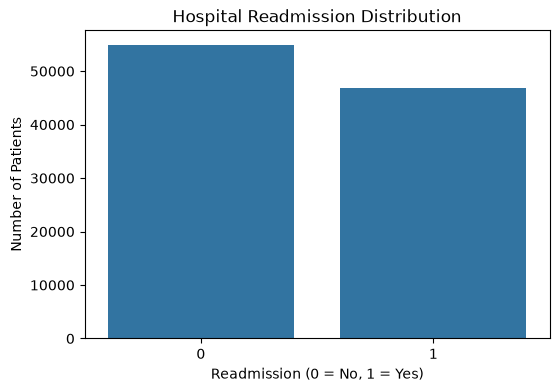

In [31]:
plt.figure(figsize=(6, 4))

sns.countplot(x="readmission", data=df)

plt.title("Hospital Readmission Distribution")
plt.xlabel("Readmission (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

In [33]:
df = df.drop(columns=["encounter_id", "patient_nbr", "readmitted"])

In [34]:
print("Number of columns:", df.shape[1])

Number of columns: 43


In [35]:
print(df.columns.tolist())

['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmission']


In [37]:
X = df.drop("readmission", axis=1)


In [38]:
y = df["readmission"]

In [39]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (101766, 42)
Target shape: (101766,)


In [40]:
X.dtypes

race                          str
gender                        str
age                           str
admission_type_id           int64
discharge_disposition_id    int64
admission_source_id         int64
time_in_hospital            int64
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
number_outpatient           int64
number_emergency            int64
number_inpatient            int64
diag_1                        str
diag_2                        str
diag_3                        str
number_diagnoses            int64
metformin                     str
repaglinide                   str
nateglinide                   str
chlorpropamide                str
glimepiride                   str
acetohexamide                 str
glipizide                     str
glyburide                     str
tolbutamide                   str
pioglitazone                  str
rosiglitazone                 str
acarbose                      str
miglitol      

In [41]:
categorical_columns = X.select_dtypes(include=["object"]).columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['race', 'gender', 'age', 'diag_1', 'diag_2', 'diag_3', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [42]:
categorical_columns = X.select_dtypes(include=["object"]).columns

print(categorical_columns.tolist())

['race', 'gender', 'age', 'diag_1', 'diag_2', 'diag_3', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [43]:
from sklearn.preprocessing import OneHotEncoder

In [44]:
X_encoded = pd.get_dummies(X, columns=categorical_columns, drop_first=True)

In [45]:
print("Original features:", X.shape)
print("Encoded features:", X_encoded.shape)

Original features: (101766, 42)
Encoded features: (101766, 2330)


In [46]:
print(X_encoded.dtypes.value_counts())

bool     2319
int64      11
Name: count, dtype: int64


In [47]:
X_encoded = X_encoded.astype(int)

In [48]:
print(X_encoded.dtypes.value_counts())

int64    2330
Name: count, dtype: int64


In [49]:
print("Missing values:", X_encoded.isnull().sum().sum())

Missing values: 0


In [50]:
print(y.value_counts())

readmission
0    54864
1    46902
Name: count, dtype: int64


In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [52]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (81412, 2330)
Testing data: (20354, 2330)


In [53]:
from sklearn.linear_model import LogisticRegression

In [54]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [55]:
logistic_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [59]:
y_pred_logistic = logistic_model.predict(X_test)

In [63]:
print(y_pred_logistic[:20])

[0 0 1 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0]


In [61]:
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy_logistic)

Logistic Regression Accuracy: 0.6301955389604009


In [64]:
print(f"Accuracy: {accuracy_logistic * 100:.2f}%")

Accuracy: 63.02%


In [65]:
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)

print(f"Precision: {precision_logistic:.4f}")
print(f"Recall:    {recall_logistic:.4f}")
print(f"F1 Score:  {f1_logistic:.4f}")

Precision: 0.6269
Recall:    0.4882
F1 Score:  0.5489


In [66]:
print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

           0       0.63      0.75      0.69     10973
           1       0.63      0.49      0.55      9381

    accuracy                           0.63     20354
   macro avg       0.63      0.62      0.62     20354
weighted avg       0.63      0.63      0.62     20354



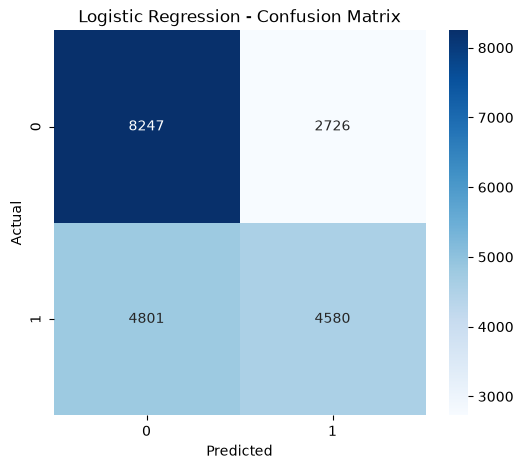

In [67]:
cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
print("df exists:", "df" in globals())
print("pandas exists:", "pd" in globals())

df exists: False
pandas exists: False


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
df = pd.read_csv("dataset/diabetic_data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [12]:
# Replace missing-value markers
df = df.replace("?", np.nan)

# Remove columns with many missing values
columns_to_remove = [
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code"
]

df = df.drop(columns=columns_to_remove)

# Fill remaining missing categorical values
for col in ["race", "diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].fillna("Unknown")

# Create binary target
df["readmission"] = df["readmitted"].apply(
    lambda x: 0 if x == "NO" else 1
)

# Remove identifiers and original target
df = df.drop(
    columns=["encounter_id", "patient_nbr", "readmitted"]
)

print("Data preparation completed!")
print(df.shape)

Data preparation completed!
(101766, 43)


In [14]:
# Separate features and target
X = df.drop("readmission", axis=1)
y = df["readmission"]

# Identify categorical columns (compatible with pandas 3.x)
categorical_columns = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Convert categorical columns into numeric columns
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
).astype(int)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Data preparation completed successfully!")

Training data: (81412, 2330)
Testing data: (20354, 2330)
Data preparation completed successfully!


In [16]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=15,
    min_samples_split=20
)

decision_tree_model.fit(X_train, y_train)

y_pred_tree = decision_tree_model.predict(X_test)

print("Decision Tree Results")
print("----------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tree) * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred_tree, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tree, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_tree, zero_division=0):.4f}")

Decision Tree Results
----------------------
Accuracy:  62.00%
Precision: 0.5997
Recall:    0.5281
F1 Score:  0.5616


In [17]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = random_forest_model.predict(X_test)

# Evaluate the model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy:  {accuracy_rf * 100:.2f}%")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1 Score:  {f1_rf:.4f}")

Random Forest Results
---------------------
Accuracy:  62.67%
Precision: 0.6789
Recall:    0.3606
F1 Score:  0.4710


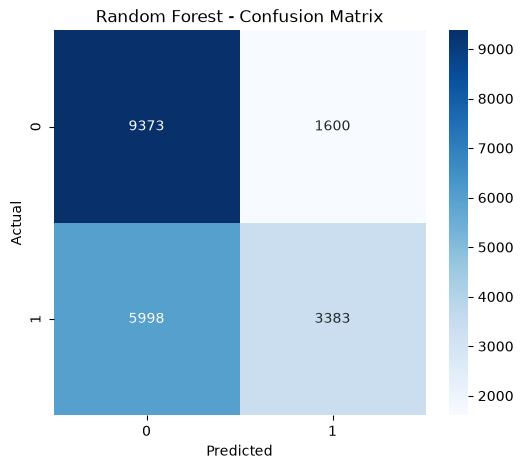

In [18]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv("dataset/diabetic_data.csv")

# Replace missing-value markers
df = df.replace("?", np.nan)

# Remove columns with many missing values
df = df.drop(columns=[
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code"
])

# Fill missing categorical values
for col in ["race", "diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].fillna("Unknown")

# Create target
df["readmission"] = df["readmitted"].apply(
    lambda x: 0 if x == "NO" else 1
)

# Remove identifiers and original target
df = df.drop(columns=[
    "encounter_id",
    "patient_nbr",
    "readmitted"
])

print("Dataset prepared:", df.shape)

Dataset prepared: (101766, 43)


In [4]:
X = df.drop("readmission", axis=1)
y = df["readmission"]

categorical_columns = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (81412, 2330)
Testing data: (20354, 2330)


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression
logistic_model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

# Predict
y_pred_logistic = logistic_model.predict(X_test_scaled)

# Evaluate
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(
    y_test, y_pred_logistic, zero_division=0
)
recall_logistic = recall_score(
    y_test, y_pred_logistic, zero_division=0
)
f1_logistic = f1_score(
    y_test, y_pred_logistic, zero_division=0
)

print("Scaled Logistic Regression Results")
print(f"Accuracy:  {accuracy_logistic * 100:.2f}%")
print(f"Precision: {precision_logistic:.4f}")
print(f"Recall:    {recall_logistic:.4f}")
print(f"F1 Score:  {f1_logistic:.4f}")

Scaled Logistic Regression Results
Accuracy:  62.68%
Precision: 0.6193
Recall:    0.4938
F1 Score:  0.5495


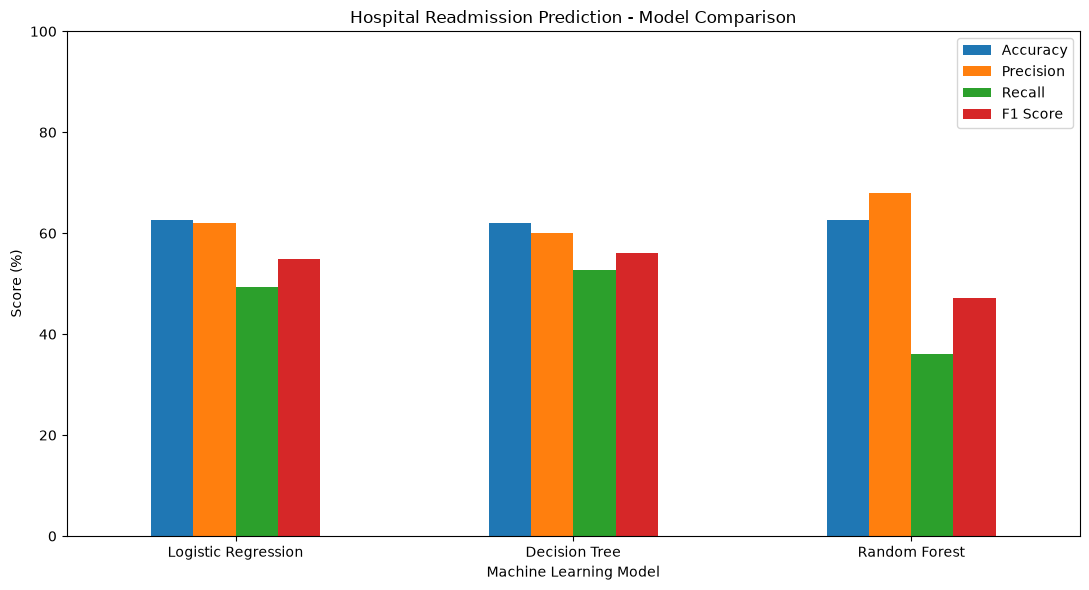

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [62.68, 62.00, 62.67],
    "Precision": [0.6193 * 100, 0.5997 * 100, 0.6789 * 100],
    "Recall": [0.4938 * 100, 0.5281 * 100, 0.3606 * 100],
    "F1 Score": [0.5495 * 100, 0.5616 * 100, 0.4710 * 100]
})

results.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Hospital Readmission Prediction - Model Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(loc="best")
plt.tight_layout()
plt.show()